# Masked Autoencoders for Unseen-Activity Detection on UCI-HAR

A self-supervised time-series experiment on real smartphone sensor recordings.

*How does the capacity of a compact masked autoencoder affect reconstruction quality and detection of an activity excluded from training?*

We train three lightweight models on five human activities and evaluate reconstruction-error scores on the held-out activity.

### 1. Import and Reproducibility

Import dependencies, set the random seed, and select CPU or GPU.

In [40]:
import io, zipfile, urllib.request, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from itertools import product
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score

SEED=42
WINDOW=128
CHANNELS=9
PATCH=8
MASK_RATIO=0.5
HIDDENS=[4,16,64]
EPOCHS=15
BATCH_SIZE=128
LEARNING_RATE=0.001
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


### 2. Load the Original UCI-HAR Sensor Windows

UCI-HAR contains recordings from 30 volunteers performing six activities, captured by smartphone accelerometer and gyroscope sensors at 50 Hz. The official split has 7,352 training and 2,947 test windows, with disjoint participants.

Each window spans 128 samples and has 9 channels, body acceleration, body gyroscope, and total acceleration along the x, y, and z axes.

In [41]:
DATA_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
CACHE = Path("uci_har_original.zip")
if not CACHE.exists():
    print("Downloading original UCI-HAR archive...")
    urllib.request.urlretrieve(DATA_URL, CACHE)
print("Archive:", CACHE, "Size (MB):", round(CACHE.stat().st_size/1e6, 1))

Archive: uci_har_original.zip Size (MB): 61.0


The UCI download contain a second ZIP file. This helper returns the archive containing the actual dataset.

In [42]:
# The UCI download contain an inner UCI HAR Dataset.zip
def open_dataset_zip(archive_path):
    outer = zipfile.ZipFile(archive_path)
    inner_names = [name for name in outer.namelist() if name.lower().endswith(".zip")]
    if inner_names:
        return zipfile.ZipFile(io.BytesIO(outer.read(inner_names[0])))
    return outer

Load each of the nine sensor channels and stack them into an array.

In [43]:
def load_split(archive, split):
    # Load the original nine inertial channels from exact archive paths
    channels = [
        f"{sensor}_{axis}"
        for sensor in ("body_acc", "body_gyro", "total_acc")
        for axis in "xyz"
    ]

    def read_text(relative_path):
        # Exact paths avoid false matches with macOS metadata and y-axis files
        path = f"UCI HAR Dataset/{relative_path}"
        if path not in archive.namelist():
            raise FileNotFoundError(f"Missing UCI-HAR file: {path}")
        return np.loadtxt(io.BytesIO(archive.read(path)))

    signals = [
        read_text(f"{split}/Inertial Signals/{channel}_{split}.txt")
        for channel in channels
    ]
    X = np.stack(signals, axis=-1).astype(np.float32)
    y = read_text(f"{split}/y_{split}.txt").astype(np.int64)
    subjects = read_text(f"{split}/subject_{split}.txt").astype(np.int64)
    return X, y, subjects

Confirm the expected shapes and check that no subject appears in both official splits.

In [44]:
with open_dataset_zip(CACHE) as archive:
    X_train_all, y_train_all, subjects_train = load_split(archive, "train")
    X_test_all, y_test_all, subjects_test = load_split(archive, "test")
print("Train:", X_train_all.shape, "Test:", X_test_all.shape)
print("Overlapping subjects:", set(subjects_train).intersection(set(subjects_test)))
assert not set(subjects_train).intersection(set(subjects_test))

Train: (7352, 128, 9) Test: (2947, 128, 9)
Overlapping subjects: set()


### 3. Define the Unseen-Class OOD Protocol

The six activity labels are: `1` WALKING, `2` WALKING_UPSTAIRS, `3` WALKING_DOWNSTAIRS, `4` SITTING, `5` STANDING, and `6` LAYING.

Experimental Split:

- Self-supervised training: all official training windows except LAYING.
- Known test set: the five retained activities from official test subjects.
- OOD test set: LAYING windows from official test subjects.

This uses labels to design the benchmark, not to train the encoder.

In [45]:
OOD_CLASS = 6
train_mask = y_train_all != OOD_CLASS
X_train = X_train_all[train_mask]
known_test = X_test_all[y_test_all != OOD_CLASS]
ood_test = X_test_all[y_test_all == OOD_CLASS]
print("Unlabeled Training Windows:", len(X_train))
print("Known Test Windows:", len(known_test), "Novel-class Test Windows:", len(ood_test))

Unlabeled Training Windows: 5945
Known Test Windows: 2410 Novel-class Test Windows: 537


Compute each channel's mean and standard deviation only from the known-class training windows, then apply the same transformation to both test sets:

$$x'_{t,c}=\frac{x_{t,c}-\mu_c}{\sigma_c}$$

This makes the channel scales more comparable without using test-set statistics.

In [46]:
def normalize_from_train(train, *others):
    # Fit statistics using known-class training windows only
    mean = train.mean(axis=(0,1), keepdims=True)
    std = train.std(axis=(0,1), keepdims=True).clip(min=1e-5)
    return ((train-mean)/std, *[(x-mean)/std for x in others])

In [47]:
X_train, known_test, ood_test = normalize_from_train(X_train, known_test, ood_test)
print("Training Mean (per channel):", np.round(X_train.mean(axis=(0,1)), 3))

Training Mean (per channel): [-0.    -0.    -0.     0.     0.    -0.     0.005  0.     0.   ]


### 4. Inspect Real Sensor Traces

Plot a representative known-activity window beside a held-out LAYING window.

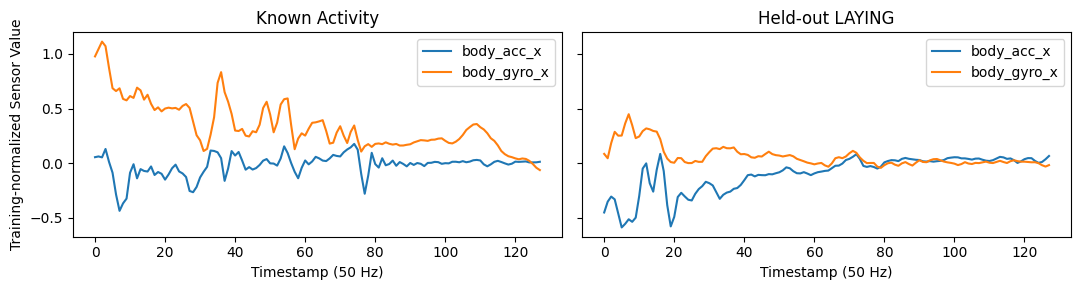

In [48]:
fig, axes = plt.subplots(1,2,figsize=(11,3),sharey=True)
for ax, sample, title in zip(axes, [known_test[0], ood_test[0]], ["Known Activity", "Held-out LAYING"]):
    ax.plot(sample[:,0],label="body_acc_x"); ax.plot(sample[:,3],label="body_gyro_x")
    ax.set_title(title); ax.set_xlabel("Timestamp (50 Hz)"); ax.legend()
axes[0].set_ylabel("Training-normalized Sensor Value")
plt.tight_layout()
plt.show()

### 5. Masked Reconstruction Model

We divide each 128-step window into 16 non-overlapping patches of 8 steps and randomly hide 50% of the patches. All nine channels in a selected patch are hidden together.

The network receives the masked signal and an explicit mask indicator, compresses them with a small fully connected encoder, and predicts the full window using a linear decoder. Loss is computed only at masked positions.

$$\mathcal{L}_{\mathrm{mask}}=\frac{\sum_{t,c}m_{t,c}(x_{t,c}-\hat{x}_{t,c})^2}{\sum_{t,c}m_{t,c}}$$

Here, $m_{t,c}=1$ denotes a hidden value. We vary only the hidden dimension to study the effect of model capacity.

A Boolean mask marks the hidden time steps. The same time steps are masked across all sensor channels.

In [49]:
def make_masks(batch_size, device, generator=None):
    # True means hidden
    n_patches = WINDOW // PATCH
    ranks = torch.rand((batch_size,n_patches), device=device, generator=generator).argsort(dim=1)
    mask = ranks < int(n_patches*MASK_RATIO)
    return mask.repeat_interleave(PATCH, dim=1).unsqueeze(-1)

The encoder maps the flattened masked window and mask indicator into a low-dimensional representation, the decoder maps that representation back to 128 × 9 values. The reported total parameter count includes both encoder and decoder.

In [50]:
class MaskedAutoencoder(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        d = WINDOW*CHANNELS
        self.encoder = nn.Sequential(nn.Linear(d+WINDOW,hidden),nn.ReLU(),nn.Linear(hidden,hidden),nn.ReLU())
        self.decoder = nn.Linear(hidden,d)

    def forward(self, x, mask):
        masked = x.masked_fill(mask,0.0)
        z = self.encoder(torch.cat([masked.flatten(1), mask.squeeze(-1).float()],dim=1))
        return self.decoder(z).reshape_as(x)

Visible values do not contribute to the training objective. This forces the model to infer missing measurements from the observed temporal context.

In [51]:
def masked_mse(prediction, target, mask):
    weights = mask.expand_as(target).float()
    return (((prediction-target)**2)*weights).sum()/weights.sum()

### 6. Train the Three Model Capacities

Train independently on unlabeled known-activity windows using Adam and the masked MSE objective. We keep the data, masking ratio, optimizer, and number of epochs fixed so capacity is the main variable.

Training loss measures reconstruction fit on masked training windows, it does not directly measure OOD detection quality.

For each hidden dimension, initialize a new model, sample masks per batch, and optimize masked reconstruction error.

In [52]:
def train_model(hidden):
    torch.manual_seed(SEED)
    model = MaskedAutoencoder(hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train)),batch_size=BATCH_SIZE,shuffle=True)
    losses=[]
    for epoch in range(EPOCHS):
        model.train(); total=0.0; count=0
        for (batch,) in loader:
            batch=batch.to(DEVICE)
            mask=make_masks(len(batch),DEVICE)
            optimizer.zero_grad()
            loss=masked_mse(model(batch,mask),batch,mask)
            loss.backward(); optimizer.step()
            total += loss.item()*len(batch); count += len(batch)
        losses.append(total/count)
    return model, losses

Train hidden dimensions 4, 16, and 64, then visualize how masked reconstruction loss changes over epochs.

In [53]:
models={}
histories={}
for hidden in HIDDENS:
    model, history=train_model(hidden)
    models[hidden]=model; histories[hidden]=history
    params=sum(p.numel() for p in model.parameters())
    print(f"hidden={hidden:2d} | params={params:,} | final masked MSE={history[-1]:.4f}")

hidden= 4 | params=10,904 | final masked MSE=0.8521
hidden=16 | params=40,352 | final masked MSE=0.6529
hidden=64 | params=161,024 | final masked MSE=0.5290


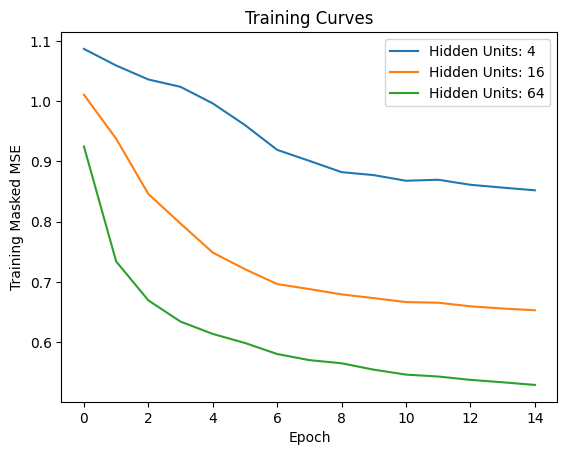

In [54]:
for hidden in HIDDENS:
    plt.plot(histories[hidden], label=f"Hidden Units: {hidden}")
plt.xlabel("Epoch")
plt.ylabel("Training Masked MSE")
plt.title("Training Curves")
plt.legend()
plt.show()

### 7. Score Known and Held-Out Activities

After training, freeze each model and score test windows using masked reconstruction error. To reduce sensitivity to any single random mask, average the per-window score over eight masking repetitions.

$$s(x)=\frac{1}{K}\sum_{k=1}^{K}\operatorname{MSE}_{\mathcal M_k}(x,\hat{x}_k),\qquad K=8$$

A larger score means the masked values were harder to reconstruct.

We evaluate AUROC and AURP using labels only after scoring.

Use a fixed random-number generator for evaluation masks so the capacity comparison is reproducible. Scores are calculated independently for known and OOD test windows.

In [55]:
def reconstruction_scores(model, X, repeats=8, batch_size=128):
    generator = torch.Generator(device="cpu").manual_seed(2026)
    model.eval(); outputs=[]
    with torch.no_grad():
        for start in range(0,len(X),batch_size):
            batch=torch.from_numpy(X[start:start+batch_size]).to(DEVICE)
            acc=torch.zeros(len(batch),device=DEVICE)
            for _ in range(repeats):
                mask=make_masks(len(batch),"cpu",generator=generator).to(DEVICE)
                pred=model(batch,mask)
                err=((pred-batch)**2)*mask.expand_as(batch)
                acc += err.sum(dim=(1,2))/mask.expand_as(batch).sum(dim=(1,2))
            outputs.append((acc/repeats).cpu().numpy())
    return np.concatenate(outputs)

Assign known windows label `0` and held-out LAYING windows label `1`.

In [56]:
def evaluate_model(model, hidden):
    normal_scores=reconstruction_scores(model,known_test)
    ood_scores=reconstruction_scores(model,ood_test)
    labels=np.r_[np.zeros(len(normal_scores)),np.ones(len(ood_scores))]
    scores=np.r_[normal_scores,ood_scores]
    return {"hidden":hidden,"AUROC":roc_auc_score(labels,scores),
            "AUPR":average_precision_score(labels,scores),
            "known_mean_MSE":normal_scores.mean(),"ood_mean_MSE":ood_scores.mean(),
            "parameters":sum(p.numel() for p in model.parameters())}, normal_scores,ood_scores

Report detection metrics, average reconstruction scores for both groups, and model parameter counts.

In [57]:
rows=[]; score_sets={}
for hidden,model in models.items():
    row,normal,ood=evaluate_model(model,hidden)
    rows.append(row);score_sets[hidden]=(normal,ood)
results=pd.DataFrame(rows)
display(results.round(4))

,hidden,AUROC,AUPR,known_mean_MSE,ood_mean_MSE,parameters
0,4,0.8779,0.6166,0.7830,2.0566,10904
1,16,0.7896,0.3740,0.6319,1.2983,40352
2,64,0.5573,0.1887,0.5394,0.5862,161024


### 8. Visualize and Interpret Score Separation

The histograms show whether known and held-out activity scores overlap.

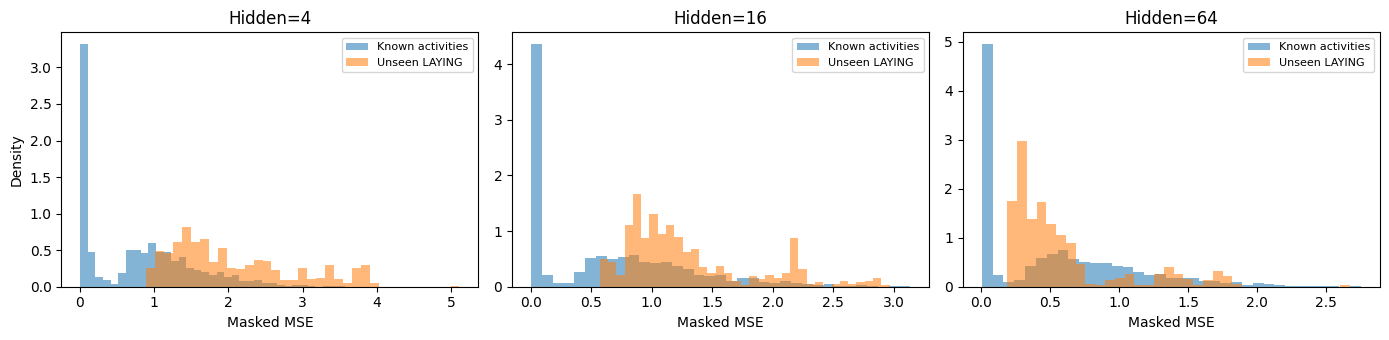

In [58]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
for ax,hidden in zip(axes,HIDDENS):
    known,ood=score_sets[hidden]
    ax.hist(known,bins=35,density=True,alpha=.55,label="Known activities")
    ax.hist(ood,bins=35,density=True,alpha=.55,label="Unseen LAYING")
    ax.set_title(f"Hidden={hidden}");ax.set_xlabel("Masked MSE");ax.legend(fontsize=8)
axes[0].set_ylabel("Density");plt.tight_layout();plt.show()

The results show a trade-off between reconstruction quality and anomaly detection performance.

As model capacity increases, reconstruction error on known activities decreases, indicating better reconstruction ability. However, anomaly detection performance also decreases because the reconstruction errors of known and unseen activities become closer.

The smallest model provides the best anomaly detection performance, despite having the highest reconstruction error on known activities. This suggests that greater model capacity does not necessarily lead to better anomaly detection.

## 9. Ablation Studies

Every experiment retrains a fresh masked autoencoder, varying just one of the following aspects at a time, which activity is held out, how many activities are seen, patch size, or masking ratio.

The models have hidden dimensions (4, 16, 64), and use three training seeds (42, 43, 44) for every condition.

In [59]:
# Ablation settings
AB_ACTIVITY_NAMES = {
    1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
    4: "SITTING", 5: "STANDING", 6: "LAYING",
}
AB_ALL_ACTIVITIES = tuple(sorted(AB_ACTIVITY_NAMES))
AB_BASE_KNOWN = (1, 2, 3, 4, 5)
AB_BASE_OOD = 6
AB_SEEN_ORDER = (1, 2, 3, 4, 5, 6)
AB_SEEN_COUNTS = (2, 3, 4, 5)
AB_PATCH_SIZES = (4, 8, 16, 32)
AB_MASK_RATIOS = (0.25, 0.50, 0.75)
AB_HIDDENS = (4, 16, 64)
AB_SEEDS = (42, 43, 44)
AB_EPOCHS = EPOCHS           # 15
AB_BATCH_SIZE = BATCH_SIZE   # 128
AB_LEARNING_RATE = LEARNING_RATE
AB_EVAL_REPEATS = 8
AB_EVAL_SEED = 2026
AB_SEEN_TRAIN_BUDGET = 2000
ab_case_cache = {}

assert WINDOW == 128 and CHANNELS == 9
assert all(WINDOW % patch == 0 for patch in AB_PATCH_SIZES)
assert set(np.unique(y_train_all)) == set(AB_ALL_ACTIVITIES)
assert set(np.unique(y_test_all)) == set(AB_ALL_ACTIVITIES)

In [60]:
# Creates the random masks used by the masked autoencoder
def ab_make_masks(batch_size, patch, mask_ratio, generator):
    if WINDOW % patch:
        raise ValueError(f"patch={patch} must divide WINDOW={WINDOW}")
    n_patches = WINDOW // patch
    n_hidden = int(n_patches * mask_ratio)
    if not 0 < n_hidden < n_patches:
        raise ValueError("Mask ratio must hide at least one but not all patches")
    rank = torch.rand((batch_size, n_patches), generator=generator).argsort(dim=1)
    return (rank < n_hidden).repeat_interleave(patch, dim=1).unsqueeze(-1)

In [61]:
# Selects which training samples the model is allowed to see
def ab_select_train_indices(known_ids, budget=None):
    if budget is None:
        return np.flatnonzero(np.isin(y_train_all, known_ids))
    allocations = divmod(budget, len(known_ids))
    sampled = []
    for position, label in enumerate(known_ids):
        count = allocations[0] + (position < allocations[1])
        candidates = np.flatnonzero(y_train_all == label)
        if len(candidates) < count:
            raise ValueError(f"Activity {label}: need {count} train windows, have {len(candidates)}")
        chooser = np.random.default_rng(2026 + int(label))
        sampled.append(chooser.choice(candidates, size=count, replace=False))
    return np.sort(np.concatenate(sampled))

In [62]:
# Prepares the training and testing datasets
def ab_get_data(known_ids, budget=None):
    # Selects the known activities for training
    train_indices = ab_select_train_indices(known_ids, budget)
    raw_train = X_train_all[train_indices]
    # Normalizes the data using the selected training windows
    mean = raw_train.mean(axis=(0, 1), keepdims=True)
    std = raw_train.std(axis=(0, 1), keepdims=True).clip(min=1e-5)
    norm = lambda values: np.asarray((values - mean) / std, dtype=np.float32)
    known_test = norm(X_test_all[np.isin(y_test_all, known_ids)])
    # Separates the known test data from each unknown activity's test data
    unknown_tests = {
        activity: norm(X_test_all[y_test_all == activity])
        for activity in AB_ALL_ACTIVITIES if activity not in known_ids
    }
    if len(known_test) == 0 or any(len(x) == 0 for x in unknown_tests.values()):
        raise ValueError("Every condition needs both known and unseen test windows")
    return norm(raw_train), known_test, unknown_tests

In [63]:
# Trains a new masked autoencoder for one experimental configuration
def ab_train(train_windows, hidden, patch, mask_ratio, seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    model = MaskedAutoencoder(hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=AB_LEARNING_RATE)
    shuffle_gen = torch.Generator().manual_seed(seed + 1000)
    mask_gen = torch.Generator().manual_seed(seed + 2000)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_windows)),
        batch_size=AB_BATCH_SIZE, shuffle=True, generator=shuffle_gen,
    )
    last_loss = np.nan
    for epoch in range(AB_EPOCHS):
        model.train()
        loss_sum = 0.0
        n_rows = 0
        for (windows,) in loader:
            windows = windows.to(DEVICE)
            masks = ab_make_masks(len(windows), patch, mask_ratio, mask_gen).to(DEVICE)
            optimizer.zero_grad()
            loss = masked_mse(model(windows, masks), windows, masks)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(windows)
            n_rows += len(windows)
        last_loss = loss_sum / n_rows
    return model, float(last_loss)

In [64]:
# Calculates how difficult each test window is for the trained model to reconstruct
def ab_scores(model, test_windows, patch, mask_ratio):
    mask_gen = torch.Generator().manual_seed(AB_EVAL_SEED)
    scores = []
    model.eval()
    with torch.no_grad():
        for begin in range(0, len(test_windows), AB_BATCH_SIZE):
            windows = torch.from_numpy(
                test_windows[begin:begin + AB_BATCH_SIZE]
            ).to(DEVICE)
            averaged = torch.zeros(len(windows), device=DEVICE)
            for _ in range(AB_EVAL_REPEATS):
                masks = ab_make_masks(len(windows), patch, mask_ratio, mask_gen).to(DEVICE)
                prediction = model(windows, masks)
                masked = masks.expand_as(windows)
                squared_error = ((prediction - windows) ** 2) * masked
                averaged += squared_error.sum(dim=(1, 2)) / masked.sum(dim=(1, 2))
            scores.append((averaged / AB_EVAL_REPEATS).cpu().numpy())
    return np.concatenate(scores)

In [65]:
# Runs one complete experimental configuration
def ab_run_case(known_ids, patch, mask_ratio, hidden, seed, budget=None):
    known_ids = tuple(sorted(map(int, known_ids)))
    key = (known_ids, int(patch), float(mask_ratio), int(hidden), int(seed), budget)
    if key not in ab_case_cache:
        train_windows, known_test, unseen_tests = ab_get_data(known_ids, budget)
        model, train_mse = ab_train(train_windows, hidden, patch, mask_ratio, seed)
        known_scores = ab_scores(model, known_test, patch, mask_ratio)
        unseen_scores = {
            activity: ab_scores(model, windows, patch, mask_ratio)
            for activity, windows in unseen_tests.items()
        }
        ab_case_cache[key] = {
            "known_scores": known_scores,
            "unseen_scores": unseen_scores,
            "train_mse": train_mse,
            "n_train": len(train_windows),
        }
        del model
    record = ab_case_cache[key]
    rows = []
    for activity, novel_scores in record["unseen_scores"].items():
        familiar_scores = record["known_scores"]
        labels = np.r_[np.zeros(len(familiar_scores)), np.ones(len(novel_scores))]
        scores = np.r_[familiar_scores, novel_scores]
        rows.append({
            "seen_count": len(known_ids),
            "seen_activities": ",".join(str(x) for x in known_ids),
            "unseen_id": activity,
            "unseen_activity": AB_ACTIVITY_NAMES[activity],
            "hidden": hidden,
            "seed": seed,
            "patch_size": patch,
            "mask_ratio": mask_ratio,
            "train_windows": record["n_train"],
            "known_test_windows": len(familiar_scores),
            "unseen_test_windows": len(novel_scores),
            "OOD_prevalence": len(novel_scores) / len(labels),
            "AUROC": roc_auc_score(labels, scores),
            "AUPR": average_precision_score(labels, scores),
            "known_mean_MSE": float(familiar_scores.mean()),
            "unseen_mean_MSE": float(novel_scores.mean()),
            "final_train_masked_MSE": record["train_mse"],
        })
    return rows

In [66]:
# Automates all the experiments in an ablation study
def ab_collect(study_name, scenarios):
    records = []
    total = len(scenarios) * len(AB_HIDDENS) * len(AB_SEEDS)
    for number, scenario in enumerate(scenarios, start=1):
        for hidden, seed in product(AB_HIDDENS, AB_SEEDS):
            rows = ab_run_case(
                known_ids=scenario["known"], patch=scenario["patch"],
                mask_ratio=scenario["mask_ratio"], hidden=hidden, seed=seed,
                budget=scenario.get("budget"),
            )
            for row in rows:
                row["study"] = study_name
                records.append(row)
        print(f"{study_name}: completed condition {number}/{len(scenarios)} "
              f"({number * len(AB_HIDDENS) * len(AB_SEEDS)}/{total} model slots)",
              flush=True)
    return pd.DataFrame.from_records(records)

In [67]:
# Converts the individual experimental results into a readable table
def ab_summary(df, group_columns):
    return (df.groupby(group_columns, as_index=False)
              .agg(AUROC_mean=("AUROC", "mean"), AUROC_std=("AUROC", "std"),
                   AUPR_mean=("AUPR", "mean"), AUPR_std=("AUPR", "std"),
                   OOD_prevalence=("OOD_prevalence", "mean"),
                   known_MSE_mean=("known_mean_MSE", "mean"),
                   unseen_MSE_mean=("unseen_mean_MSE", "mean"),
                   train_windows=("train_windows", "first")))

In [68]:
# Produces the comparison graphs
def ab_plot_comparison(df, x_column, title, x_name, activity_ticks=False):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    for ax, metric in zip(axes, ("AUROC", "AUPR")):
        for hidden in AB_HIDDENS:
            sub = (df[df["hidden"] == hidden]
                   .groupby(x_column, as_index=False)[metric]
                   .agg(["mean", "std"]).reset_index())
            ax.errorbar(sub[x_column], sub["mean"],
                        yerr=sub["std"].fillna(0), marker="o",
                        capsize=3, label=f"hidden={hidden}")
        ax.set(xlabel=x_name, ylabel=metric, ylim=(-0.02, 1.02))
        ax.grid(alpha=0.25)
        ax.legend()
        if activity_ticks:
            ax.set_xticks(AB_ALL_ACTIVITIES)
            ax.set_xticklabels([AB_ACTIVITY_NAMES[x] for x in AB_ALL_ACTIVITIES],
                               rotation=35, ha="right")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [69]:
def ab_plot_seen_per_unseen(df):
    # Every unseen class is shown separately
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey="row")
    for col, hidden in enumerate(AB_HIDDENS):
        for row, metric in enumerate(("AUROC", "AUPR")):
            ax = axes[row, col]
            for unseen_id in sorted(df["unseen_id"].unique()):
                part = df[(df["hidden"] == hidden) &
                          (df["unseen_id"] == unseen_id)]
                if part.empty:
                    continue
                grouped = (part.groupby("seen_count")[metric]
                           .agg(["mean", "std"]).reset_index())
                ax.errorbar(grouped["seen_count"], grouped["mean"],
                            yerr=grouped["std"].fillna(0), marker="o", capsize=2,
                            label=AB_ACTIVITY_NAMES[unseen_id])
            ax.set_title(f"hidden={hidden} · {metric}")
            ax.set_xticks(AB_SEEN_COUNTS)
            ax.set_ylim(-0.02, 1.02)
            ax.grid(alpha=0.25)
            if row == 1:
                ax.set_xlabel("Number of seen activities")
            if col == 0:
                ax.set_ylabel(metric)
            if row == 0 and col == 2:
                ax.legend(loc="best", fontsize=8)
    fig.suptitle("Seen-activity count: detection of each excluded activity", y=1.01)
    fig.tight_layout()
    plt.show()

### Which Single Activity is Unknown?

Hold out each of the six activities in turn, train on the other five.

In [70]:
ab_scenarios_A = [
    {"known": tuple(a for a in AB_ALL_ACTIVITIES if a != unseen),
     "patch": 8, "mask_ratio": 0.50}
    for unseen in AB_ALL_ACTIVITIES
]
ab_results_A = ab_collect("A: unknown activity", ab_scenarios_A)
ab_table_A = ab_summary(ab_results_A, ["unseen_id", "unseen_activity", "hidden"])
print("A - mean ± standard deviation across three seeds, one unknown activity per row")
display(ab_table_A.round(4))

A: unknown activity: completed condition 1/6 (9/54 model slots)
A: unknown activity: completed condition 2/6 (18/54 model slots)
A: unknown activity: completed condition 3/6 (27/54 model slots)
A: unknown activity: completed condition 4/6 (36/54 model slots)
A: unknown activity: completed condition 5/6 (45/54 model slots)
A: unknown activity: completed condition 6/6 (54/54 model slots)
A - mean ± standard deviation across three seeds, one unknown activity per row


,unseen_id,unseen_activity,hidden,AUROC_mean,AUROC_std,AUPR_mean,AUPR_std,OOD_prevalence,known_MSE_mean,unseen_MSE_mean,train_windows
0,1,WALKING,4,0.7362,0.0006,0.2576,0.0005,0.1683,0.7046,1.3108,6126
1,1,WALKING,16,0.7681,0.0005,0.2858,0.0006,0.1683,0.5484,1.1714,6126
2,1,WALKING,64,0.7934,0.0006,0.3208,0.0004,0.1683,0.4736,1.1248,6126
3,2,WALKING_UPSTAIRS,4,0.8255,0.0011,0.3344,0.0012,0.1598,0.6992,1.6829,6279
4,2,WALKING_UPSTAIRS,16,0.8360,0.0005,0.3442,0.0004,0.1598,0.5652,1.5189,6279
5,2,WALKING_UPSTAIRS,64,0.8435,0.0012,0.3676,0.0043,0.1598,0.4823,1.3639,6279
6,3,WALKING_DOWNSTAIRS,4,0.8876,0.0027,0.5276,0.0092,0.1425,0.7043,2.2095,6366
7,3,WALKING_DOWNSTAIRS,16,0.9093,0.0004,0.6058,0.0004,0.1425,0.5359,2.0713,6366
8,3,WALKING_DOWNSTAIRS,64,0.9265,0.0003,0.6611,0.0037,0.1425,0.4407,1.9253,6366
9,4,SITTING,4,0.2559,0.0063,0.1102,0.0009,0.1666,0.6930,0.0909,6066


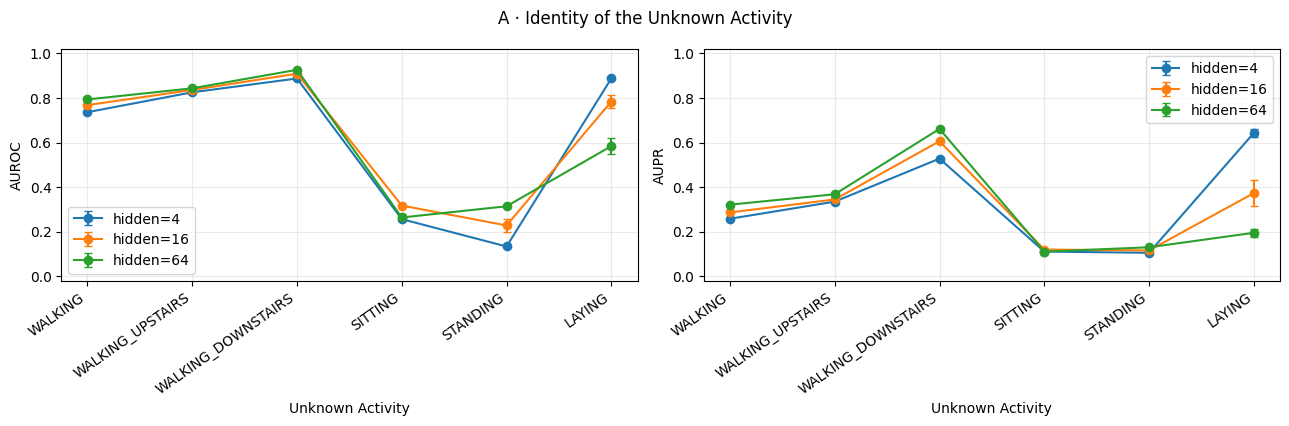

In [71]:
ab_plot_comparison(ab_results_A, "unseen_id", "A · Identity of the Unknown Activity",
                   "Unknown Activity", activity_ticks=True)

### How Many Activities are Seen?

The training groups are `{1,2}`, `{1,2,3}`, `{1,2,3,4}`, and `{1,2,3,4,5}`, for each group, every excluded class remains unknown.

In [72]:
ab_scenarios_B = [
    {"known": AB_SEEN_ORDER[:seen_count], "patch": 8, "mask_ratio": 0.50,
     "budget": AB_SEEN_TRAIN_BUDGET}
    for seen_count in AB_SEEN_COUNTS
]
ab_results_B = ab_collect("B: number seen", ab_scenarios_B)
ab_table_B = ab_summary(ab_results_B,
    ["seen_count", "seen_activities", "unseen_id", "unseen_activity", "hidden"])
print("B - PER-UNSEEN-ACTIVITY - Each excluded activity is evaluated separately")
display(ab_table_B.round(4))

B: number seen: completed condition 1/4 (9/36 model slots)
B: number seen: completed condition 2/4 (18/36 model slots)
B: number seen: completed condition 3/4 (27/36 model slots)
B: number seen: completed condition 4/4 (36/36 model slots)
B - PER-UNSEEN-ACTIVITY - Each excluded activity is evaluated separately


,seen_count,seen_activities,unseen_id,unseen_activity,hidden,AUROC_mean,AUROC_std,AUPR_mean,AUPR_std,OOD_prevalence,known_MSE_mean,unseen_MSE_mean,train_windows
0,2,"1,2",3,WALKING_DOWNSTAIRS,4,0.7201,0.0027,0.5310,0.0042,0.3028,0.8983,1.2096,2000
1,2,"1,2",3,WALKING_DOWNSTAIRS,16,0.7654,0.0001,0.5991,0.0037,0.3028,0.7041,1.0921,2000
2,2,"1,2",3,WALKING_DOWNSTAIRS,64,0.8204,0.0016,0.6901,0.0016,0.3028,0.5526,0.9852,2000
3,2,"1,2",4,SITTING,4,0.2775,0.0045,0.2681,0.0035,0.3368,0.8983,0.6077,2000
4,2,"1,2",4,SITTING,16,0.1944,0.0282,0.2245,0.0104,0.3368,0.7041,0.3597,2000
5,2,"1,2",4,SITTING,64,0.0246,0.0019,0.1922,0.0001,0.3368,0.5526,0.0920,2000
6,2,"1,2",5,STANDING,4,0.0039,0.0001,0.2036,0.0000,0.3549,0.8983,0.1457,2000
7,2,"1,2",5,STANDING,16,0.0053,0.0016,0.2036,0.0000,0.3549,0.7041,0.0688,2000
8,2,"1,2",5,STANDING,64,0.0026,0.0000,0.2036,0.0000,0.3549,0.5526,0.0324,2000
9,2,"1,2",6,LAYING,4,1.0000,0.0000,1.0000,0.0000,0.3570,0.8983,5.1875,2000


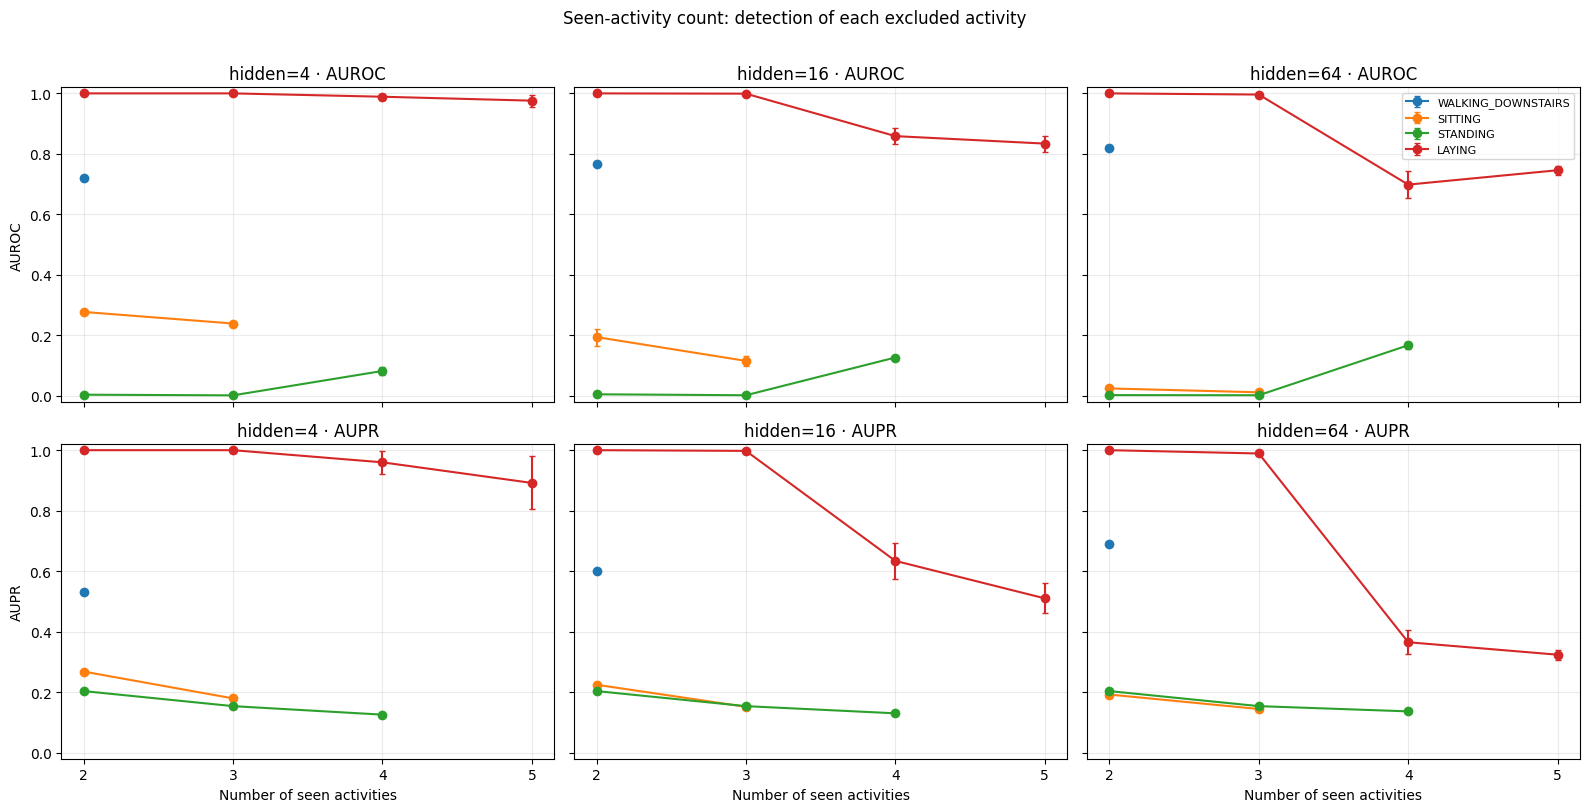

In [73]:
ab_plot_seen_per_unseen(ab_results_B)

B - Descriptive macro-average across unseen activities, then across seeds.


,seen_count,hidden,AUROC_mean,AUROC_std,AUPR_mean,AUPR_std
0,2,4,0.5004,0.0013,0.5007,0.0015
1,2,16,0.4913,0.0075,0.5068,0.0018
2,2,64,0.4619,0.0009,0.5215,0.0004
3,3,4,0.4137,0.0020,0.4444,0.0010
4,3,16,0.3723,0.0060,0.4344,0.0014
5,3,64,0.3367,0.0007,0.4290,0.0011
6,4,4,0.5357,0.0021,0.5428,0.0182
7,4,16,0.4928,0.0130,0.3821,0.0303
8,4,64,0.4329,0.0202,0.2508,0.0196
9,5,4,0.9759,0.0201,0.8917,0.0875


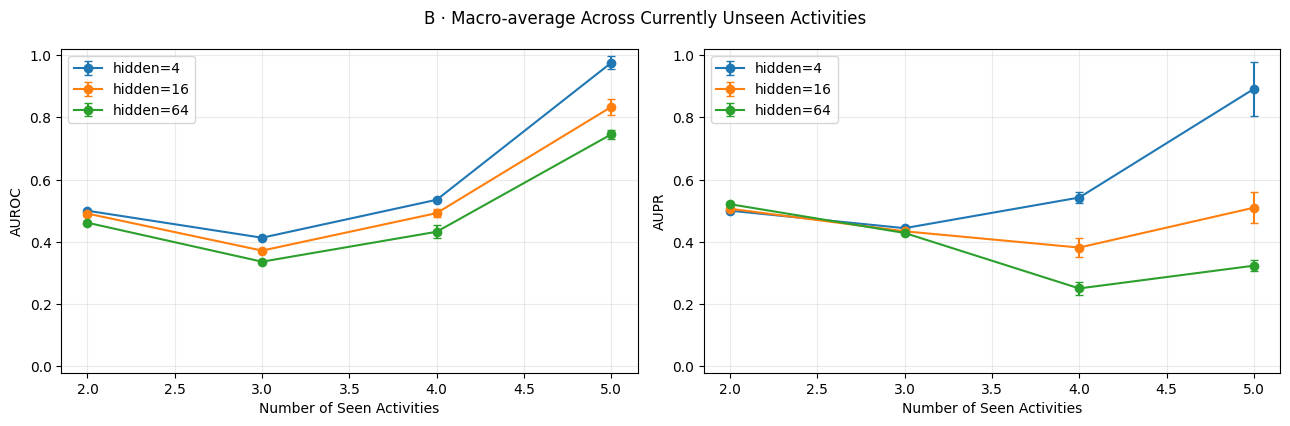

In [74]:
# Aggregate across unseen activities
ab_macro_B = (ab_results_B.groupby(["seen_count", "hidden", "seed"], as_index=False)
              .agg(AUROC=("AUROC", "mean"), AUPR=("AUPR", "mean")))
ab_table_B_macro = (ab_macro_B.groupby(["seen_count", "hidden"], as_index=False)
                    .agg(AUROC_mean=("AUROC", "mean"), AUROC_std=("AUROC", "std"),
                         AUPR_mean=("AUPR", "mean"), AUPR_std=("AUPR", "std")))
print("B - Descriptive macro-average across unseen activities, then across seeds.")
display(ab_table_B_macro.round(4))
ab_plot_comparison(ab_macro_B, "seen_count",
                   "B · Macro-average Across Currently Unseen Activities",
                   "Number of Seen Activities")

### Patch Size

Vary only patch size ∈ {4, 8, 16, 32}. The window remains 128 time steps, so all patch sizes divide it exactly.

In [36]:
ab_scenarios_C = [
    {"known": AB_BASE_KNOWN, "patch": patch, "mask_ratio": 0.50}
    for patch in AB_PATCH_SIZES
]
ab_results_C = ab_collect("C: patch size", ab_scenarios_C)
ab_table_C = ab_summary(ab_results_C, ["patch_size", "hidden"])
print("C - Patch Size: Mean ± standard deviation across seeds.")
display(ab_table_C.round(4))

C: patch size: completed condition 1/4 (9/36 model slots)
C: patch size: completed condition 2/4 (18/36 model slots)
C: patch size: completed condition 3/4 (27/36 model slots)
C: patch size: completed condition 4/4 (36/36 model slots)
C - Patch Size: Mean ± standard deviation across seeds.


,patch_size,hidden,AUROC_mean,AUROC_std,AUPR_mean,AUPR_std,OOD_prevalence,known_MSE_mean,unseen_MSE_mean,train_windows
0,4,4,0.8924,0.0077,0.6601,0.0257,0.1822,0.7819,2.1752,5945
1,4,16,0.8156,0.0114,0.4266,0.0238,0.1822,0.6164,1.3598,5945
2,4,64,0.5669,0.0201,0.1856,0.0078,0.1822,0.5099,0.5457,5945
3,8,4,0.8876,0.0048,0.6428,0.0174,0.1822,0.7807,2.1143,5945
4,8,16,0.7841,0.0297,0.3727,0.0579,0.1822,0.6312,1.2849,5945
5,8,64,0.5837,0.0368,0.1944,0.0186,0.1822,0.5382,0.6169,5945
6,16,4,0.8779,0.0119,0.6141,0.0367,0.1822,0.7843,2.0522,5945
7,16,16,0.7978,0.0317,0.3913,0.0490,0.1822,0.6496,1.3659,5945
8,16,64,0.5755,0.0136,0.2017,0.0151,0.1822,0.5642,0.6581,5945
9,32,4,0.8779,0.0085,0.6211,0.0247,0.1822,0.7892,2.0844,5945


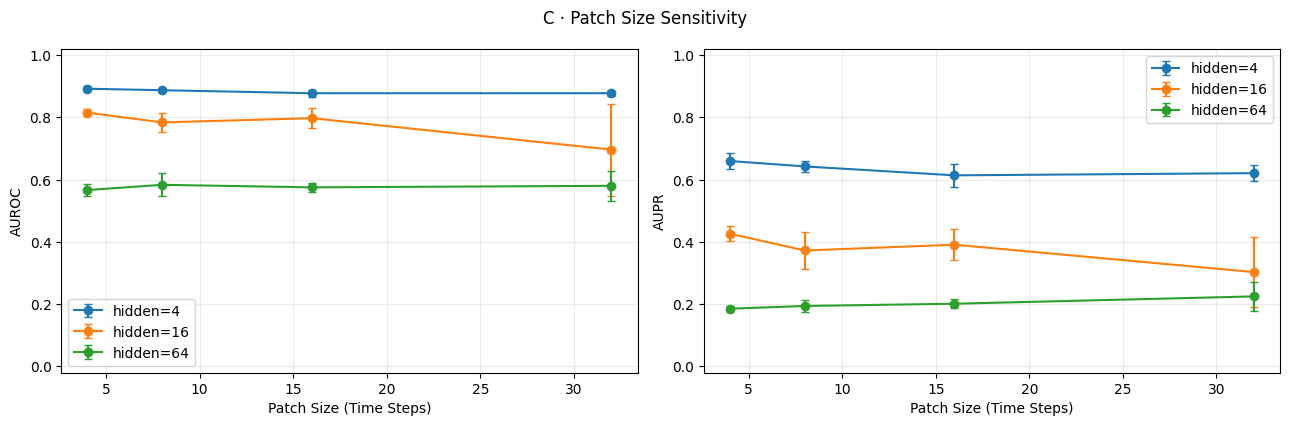

In [37]:
ab_plot_comparison(ab_results_C, "patch_size", "C · Patch Size Sensitivity",
                   "Patch Size (Time Steps)")

### Masking Ratio

Vary only mask ratio ∈ {0.25, 0.50, 0.75}.

In [38]:
ab_scenarios_D = [
    {"known": AB_BASE_KNOWN, "patch": 8, "mask_ratio": ratio}
    for ratio in AB_MASK_RATIOS
]
ab_results_D = ab_collect("D: masking ratio", ab_scenarios_D)
ab_table_D = ab_summary(ab_results_D, ["mask_ratio", "hidden"])
print("D - Masking Ratio: mean ± standard deviation across seeds.")
display(ab_table_D.round(4))

D: masking ratio: completed condition 1/3 (9/27 model slots)
D: masking ratio: completed condition 2/3 (18/27 model slots)
D: masking ratio: completed condition 3/3 (27/27 model slots)
D - Masking Ratio: mean ± standard deviation across seeds.


,mask_ratio,hidden,AUROC_mean,AUROC_std,AUPR_mean,AUPR_std,OOD_prevalence,known_MSE_mean,unseen_MSE_mean,train_windows
0,0.25,4,0.8784,0.0043,0.6242,0.0118,0.1822,0.7824,2.0854,5945
1,0.25,16,0.7948,0.0061,0.3949,0.0174,0.1822,0.6302,1.3276,5945
2,0.25,64,0.6189,0.0037,0.2160,0.0030,0.1822,0.5216,0.6898,5945
3,0.50,4,0.8876,0.0048,0.6428,0.0174,0.1822,0.7807,2.1143,5945
4,0.50,16,0.7841,0.0297,0.3727,0.0579,0.1822,0.6312,1.2849,5945
5,0.50,64,0.5837,0.0368,0.1944,0.0186,0.1822,0.5382,0.6169,5945
6,0.75,4,0.8672,0.0285,0.6060,0.0576,0.1822,0.7912,2.0368,5945
7,0.75,16,0.7748,0.0553,0.3721,0.0786,0.1822,0.6607,1.3275,5945
8,0.75,64,0.5552,0.0251,0.1881,0.0155,0.1822,0.5869,0.6229,5945


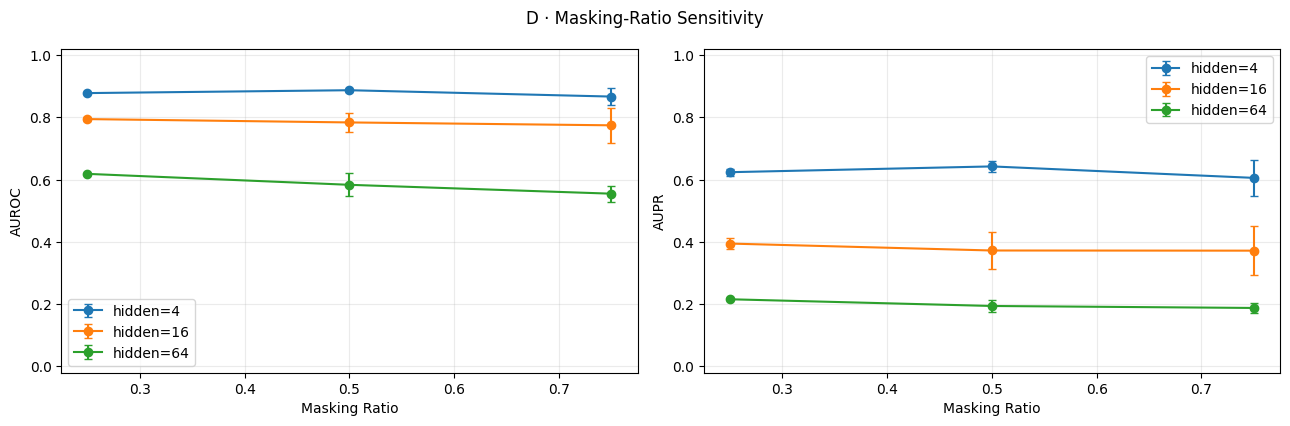

In [39]:
ab_plot_comparison(ab_results_D, "mask_ratio", "D · Masking-Ratio Sensitivity",
                   "Masking Ratio")

### Conclusion and Key Findings

This study investigated how the capacity of a compact masked autoencoder affects reconstruction quality and the detection of human activities excluded from training.

The results show that increasing the hidden dimension from 4 to 64 generally improves reconstruction quality. However, better reconstruction does not necessarily lead to better unseen-activity detection.

The ablation studies showed that the number and identity of seen activities influence detection performance, while patch size and masking ratio have comparatively smaller effects.

Overall, these findings demonstrate that improving reconstruction accuracy does not guarantee better novelty detection, and the most suitable autoencoder capacity depends on the characteristics of the excluded activity.

This highlights an important limitation of reconstruction-error-based activity detection and suggests that model capacity should be selected based on detection performance rather than reconstruction loss alone.